# Earthwise Butchery Image Classification MLOps Project

This project classifies labelled meat-product photos into three practical groups: **red meat**, **poultry**, and **fish**. The model learns from images, not tabular feature rows. The notebook covers data setup, preprocessing, image insights, hyperparameter tuning, evaluation, and single-image prediction.

The source folder is a mixed collection, not a labelled training dataset. Review photos with `scripts/label_images.py` first. Skip spices, eggs, screenshots, mixed dishes, and unclear images.

In [1]:
import os
import sys
import zipfile
from pathlib import Path

# In Colab, clone the source repository and upload the locally labelled image ZIP.
if 'COLAB_RELEASE_TAG' in os.environ:
    os.chdir('/content')
    project_dir = Path('/content/kudakwashe-mlops-classification-pipeline')
    if not (project_dir / 'scripts' / 'train.py').is_file():
        if project_dir.exists():
            !rm -rf /content/kudakwashe-mlops-classification-pipeline
        !git clone https://github.com/kudakwashechikovo17/kudakwashe-mlops-classification-pipeline.git /content/kudakwashe-mlops-classification-pipeline
    required = [project_dir / 'requirements.txt', project_dir / 'src' / 'model.py']
    missing = [str(path) for path in required if not path.is_file()]
    if missing:
        raise RuntimeError(f'Project clone is incomplete; missing: {missing}')
    os.chdir(project_dir)
    %pip install -q -r requirements.txt

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'train.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Could not find the project folder containing scripts/train.py.')
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / 'data'
LABELED_DIR = DATA_DIR / 'labeled'
CLASS_NAMES = ('red_meat', 'poultry', 'fish')

if 'COLAB_RELEASE_TAG' in os.environ and not all((LABELED_DIR / name).is_dir() for name in CLASS_NAMES):
    from google.colab import files
    print('Upload earthwise_labeled.zip. It must contain red_meat/, poultry/, and fish/ folders.')
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if not zip_names:
        raise FileNotFoundError('No ZIP uploaded. Label the photos locally, zip the three class folders, and run this cell again.')
    with zipfile.ZipFile(zip_names[0]) as archive:
        extraction_root = LABELED_DIR.resolve()
        for member in archive.infolist():
            destination = (extraction_root / member.filename).resolve()
            try:
                destination.relative_to(extraction_root)
            except ValueError as exc:
                raise ValueError(f'Unsafe archive path: {member.filename}') from exc
        archive.extractall(extraction_root)

missing_classes = [name for name in CLASS_NAMES if not (LABELED_DIR / name).is_dir()]
if missing_classes:
    raise FileNotFoundError(f'Missing labelled folders {missing_classes}. Run scripts/label_images.py first.')

if not (DATA_DIR / 'train').is_dir() and not (DATA_DIR / 'test').is_dir():
    from scripts.prepare_dataset import prepare_dataset
    print('Created stratified split:', prepare_dataset())
print('Project root detected.')
print('Labelled class counts:', {name: sum(1 for path in (LABELED_DIR / name).iterdir() if path.is_file()) for name in CLASS_NAMES})

Project root detected.
Labelled class counts: {'red_meat': 44, 'poultry': 30, 'fish': 9}


## 1. Data acquisition and preprocessing

Photos are reviewed and assigned to `red_meat`, `poultry`, or `fish`. Exact duplicate files are excluded by the labelling tool. The preparation script creates a reproducible 80/20 train/test split with a fixed seed. Images are EXIF-corrected, converted to RGB, resized, normalized, and represented by low-resolution RGB pixels plus per-channel color histograms.

Training feature matrix: (66, 792)
Test feature matrix: (17, 792)
Training images per class: {'fish': 7, 'poultry': 24, 'red_meat': 35}


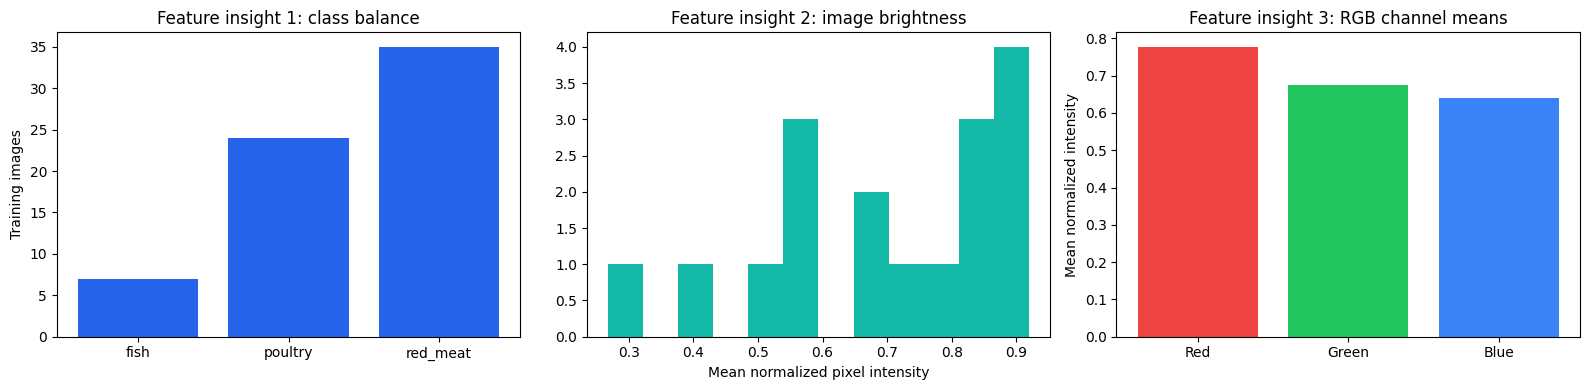

Interpretation: class balance reveals collection gaps; brightness and channel means describe image appearance but can also reflect lighting/background bias.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from src.preprocessing import IMAGE_EXTENSIONS, load_classification_split, preprocess_image

TRAIN_DIR = DATA_DIR / 'train'
TEST_DIR = DATA_DIR / 'test'
X_train, y_train, class_names = load_classification_split(TRAIN_DIR)
X_test, y_test, test_class_names = load_classification_split(TEST_DIR, class_names)
assert class_names == test_class_names, 'Train/test class order differs.'
class_counts = {name: int((y_train == index).sum()) for index, name in enumerate(class_names)}
print('Training feature matrix:', X_train.shape)
print('Test feature matrix:', X_test.shape)
print('Training images per class:', class_counts)

test_pixels = []
for name in class_names:
    paths = [p for p in sorted((TEST_DIR / name).iterdir()) if p.suffix.lower() in IMAGE_EXTENSIONS]
    for path in paths[:100]:
        with Image.open(path) as image:
            test_pixels.append(preprocess_image(image))
test_pixels = np.stack(test_pixels)
brightness = test_pixels.mean(axis=(1, 2, 3))
channel_means = test_pixels.mean(axis=(0, 1, 2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(class_counts.keys(), class_counts.values(), color='#2563eb')
axes[0].set_title('Feature insight 1: class balance')
axes[0].set_ylabel('Training images')
axes[1].hist(brightness, bins=12, color='#14b8a6')
axes[1].set_title('Feature insight 2: image brightness')
axes[1].set_xlabel('Mean normalized pixel intensity')
axes[2].bar(['Red', 'Green', 'Blue'], channel_means, color=['#ef4444', '#22c55e', '#3b82f6'])
axes[2].set_title('Feature insight 3: RGB channel means')
axes[2].set_ylabel('Mean normalized intensity')
plt.tight_layout()
plt.show()
print('Interpretation: class balance reveals collection gaps; brightness and channel means describe image appearance but can also reflect lighting/background bias.')

## 2. Model creation and optimization

A standardized stochastic-gradient classifier with logistic loss is used. L2 regularization is controlled by `alpha`. A three-fold stratified `GridSearchCV` compares three regularization strengths using macro-F1, which gives each class equal importance. The final model is refit on the complete training split and saved for API prediction and incremental retraining.

In [3]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from src.model import build_model, evaluate, save_model

counts = np.bincount(y_train, minlength=len(class_names))
if np.any(counts < 3):
    raise ValueError('Each class needs at least three training images for three-fold tuning; add and label more photos.')
search = GridSearchCV(
    estimator=build_model(),
    param_grid={'sgdclassifier__alpha': [1e-5, 1e-4, 1e-3]},
    scoring='f1_macro',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=1,
    refit=True,
)
search.fit(X_train, y_train)
model = search.best_estimator_
metrics = evaluate(model, X_test, y_test, class_names)
metrics.update({'best_params': search.best_params_, 'training_samples': int(len(y_train)), 'test_samples': int(len(y_test))})
metrics['image_insights'] = {
    'class_names': class_names,
    'class_counts': [int((y_test == index).sum()) for index in range(len(class_names))],
    'feature_names': ['Mean brightness', 'Red channel', 'Green channel', 'Blue channel'],
    'feature_values': [float(test_pixels.mean()), *[float(test_pixels[:, :, :, channel].mean()) for channel in range(3)]],
}
save_model(model, metrics, class_names)
print('Best parameters:', search.best_params_)
print({name: round(metrics[name], 4) for name in ('accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro', 'f1_macro')})
print('Saved model: models/earthwise_meat_model.pkl')

Best parameters: {'sgdclassifier__alpha': 1e-05}
{'accuracy': 0.7647, 'balanced_accuracy': 0.8519, 'precision_macro': 0.7778, 'recall_macro': 0.8519, 'f1_macro': 0.7714}
Saved model: models/earthwise_meat_model.pkl


## 3. Model testing and evaluation

The held-out test images are not used in hyperparameter selection. Report accuracy, balanced accuracy, macro-precision, macro-recall, macro-F1, the class-by-class report, and the confusion matrix. Results must be interpreted from the executed notebook; no performance is assumed in advance.

accuracy: 0.7647
balanced_accuracy: 0.8519
precision_macro: 0.7778
recall_macro: 0.8519
f1_macro: 0.7714

Per-class report:
fish {'precision': 0.6666666666666666, 'recall': 1.0, 'f1-score': 0.8, 'support': 2.0}
poultry {'precision': 0.6666666666666666, 'recall': 1.0, 'f1-score': 0.8, 'support': 6.0}
red_meat {'precision': 1.0, 'recall': 0.5555555555555556, 'f1-score': 0.7142857142857143, 'support': 9.0}


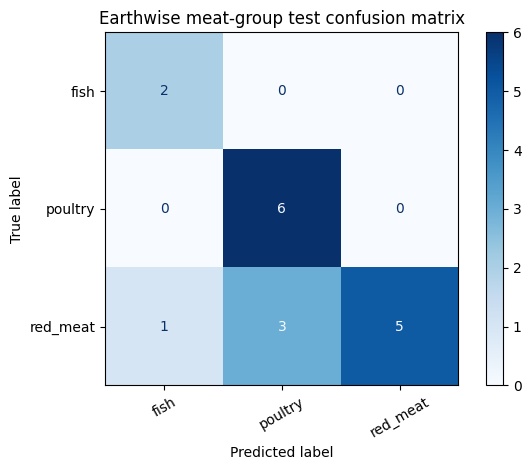

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay

for metric in ('accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro', 'f1_macro'):
    print(f'{metric}: {metrics[metric]:.4f}')
print('\nPer-class report:')
for name in class_names:
    print(name, metrics['classification_report'][name])
ConfusionMatrixDisplay(np.asarray(metrics['confusion_matrix']), display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
plt.title('Earthwise meat-group test confusion matrix')
plt.tight_layout()
plt.show()

## 4. Single-image prediction and production pipeline

The following cell predicts one held-out image and compares the output with its folder label. The FastAPI application exposes the same prediction function, a browser UI, health and metrics routes, image uploads, and a retraining trigger. Uploaded labelled images are saved in SQLite and class-specific folders before `partial_fit` updates the existing model.

In [5]:
from src.prediction import predict_image

sample_path = next(path for name in class_names for path in sorted((TEST_DIR / name).iterdir()) if path.suffix.lower() in IMAGE_EXTENSIONS)
with sample_path.open('rb') as image_file:
    prediction = predict_image(image_file.read())
actual = sample_path.parent.name
print('Image:', sample_path.name)
print('Actual:', actual)
print('Predicted:', prediction['prediction'])
print('Confidence:', round(prediction['confidence'], 4))
print('Top predictions:', prediction['top_predictions'])

Image: 52598daf34348a0f.jpg
Actual: fish
Predicted: fish
Confidence: 1.0
Top predictions: [{'label': 'fish', 'confidence': 1.0}, {'label': 'red_meat', 'confidence': 0.0}, {'label': 'poultry', 'confidence': 0.0}]


## 5. Retraining and deployment checklist

- Start the web app with `uvicorn app.main:app --host 0.0.0.0 --port 8000` and open `/` or `/docs`.
- Upload new photos with the correct class; the API records each upload and saves it in `data/uploads/<class-id>/`.
- Press **Trigger retraining**. The saved fitted classifier is updated with `partial_fit`; inspect `/retrain/status` for history.
- For Locust, run `locust -f locustfile.py --host http://127.0.0.1:8000` and record results at 10, 50, and 100 users. Do not invent latency or deployment results.
- Keep the labelled dataset private/local; it is not included in the repository. Deploy only after training and checking the measured test metrics.